# Umbral de aceptación: círculos PCA y distancia real

Este complemento de la guía 02 muestra el modelo combinado fijo: 36 características y umbral aproximado **4,1360**. Las figuras usan las **115 consultas de validación** (45 autorizadas y 70 intrusas). PCA se ajusta únicamente con las 180 autorizadas de entrenamiento. No se reentrena K-means ni se modifica el umbral.

## ¿Cómo obtuvimos el umbral?

K-means aprende centroides, pero **no decide por sí solo cuándo rechazar un intruso**. Para cada captura de validación medimos la distancia al centroide más cercano, usando las 36 características seleccionadas y estandarizadas.

Probamos umbrales entre distancias consecutivas ordenadas y los extremos. Para cada uno calculamos:

$$FAR=\frac{\text{intrusas aceptadas}}{\text{intrusas evaluadas}},\qquad FRR=\frac{\text{autorizadas rechazadas}}{\text{autorizadas evaluadas}}.$$

Elegimos el menor error balanceado $(FAR+FRR)/2$. En empate, menor FAR y luego menor umbral. El elegido se guarda: **no se vuelve a calibrar con cada consulta**. Este criterio asigna igual peso a ambas tasas; es una decisión del proyecto.

$$\boxed{d_{min}\leq\tau:\ AUTORIZADO\qquad d_{min}>\tau:\ NO\ AUTORIZADO}$$

**En la frontera se acepta.** Se compara el valor numérico completo, no su versión redondeada en pantalla. Dos valores que se ven iguales al mostrar tres decimales pueden ser distintos al compararlos. No se agregó una tolerancia extra de aceptación.


In [8]:
from pathlib import Path
import csv, json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.lines import Line2D
from sklearn.decomposition import PCA

# Abrir esta carpeta como directorio de trabajo en VS Code/Jupyter.
BASE = Path(".")
z = np.load(BASE / "huellas_desarrollo.npz")
with (BASE / "huellas_catalogo.csv").open(encoding="utf-8-sig") as f:
    filas = list(csv.DictReader(f))
identidad = np.array([r["identidad"] for r in filas])
grupo_real = np.array([r["grupo"] for r in filas])
train = np.array([r["particion"] == "entrenamiento" for r in filas])
val = ~train
Z = (z["X"][:, z["indices"]] - z["media"]) / z["escala"]
centros = z["centroides"]
tau = json.loads((BASE / "pca_resumen.json").read_text())["umbral"]
distancias = np.linalg.norm(Z[:, None, :] - centros[None, :, :], axis=2)
dmin = distancias.min(axis=1)
aceptada = dmin <= tau
pca = PCA(svd_solver="full").fit(Z[train])
P = pca.transform(Z)
C = pca.transform(centros)
colores = {"A01":"#2563EB", "A02":"#0D9488", "A03":"#9333EA",
           "I01":"#DC2626", "I02":"#EA580C"}
plt.rcParams.update({"font.size": 12, "figure.dpi": 120,
                     "axes.spines.top": False, "axes.spines.right": False})


## Gráfico principal para explicar el rechazo: círculo con distancia completa

**Este es el gráfico recomendado para defender el criterio de acceso.** No se ocultan muestras, no se cambian intrusas y no se altera el umbral. Se muestran las mismas 115 consultas de validación.

Para cada muestra se toma el **centroide más cercano calculado en 36 dimensiones**. Se mide su diferencia respecto de ese centroide y se separa en dos partes:

- Eje horizontal: longitud de la diferencia en el plano PC1–PC2.
- Eje vertical: longitud de la diferencia en las otras 34 direcciones perpendiculares.

$$x=\sqrt{\Delta PC1^2+\Delta PC2^2},\qquad y=\sqrt{d_{36}^2-x^2}.$$

Por tanto, **no perdemos ninguna parte de la distancia**:

$$\boxed{x^2+y^2=d_{36}^2.}$$

Ambos ejes se dividen por el umbral para que el arco tenga radio 1. La zona verde cumple $x^2+y^2\leq1$ y representa aceptación. Fuera del arco se rechaza. El borde está incluido. Los puntos están en el primer cuadrante porque ambas coordenadas son longitudes no negativas.

**Esto no es un PCA bidimensional convencional.** Es una representación exacta de la distancia de cada muestra a su centroide asignado. El origen representa el centroide de referencia de cada muestra; no significa que los tres centroides reales coincidan. Las distancias entre puntos de este gráfico no reproducen las distancias entre huellas originales.

Los colores indican identidades reales; círculos pequeños indican aceptadas y cruces rechazadas. Aparecen las 70 intrusas fuera, 44 autorizadas dentro y una autorizada fuera (falso rechazo). El falso rechazo se conserva: no todas las autorizadas deben aparecer dentro para que el gráfico sea correcto.


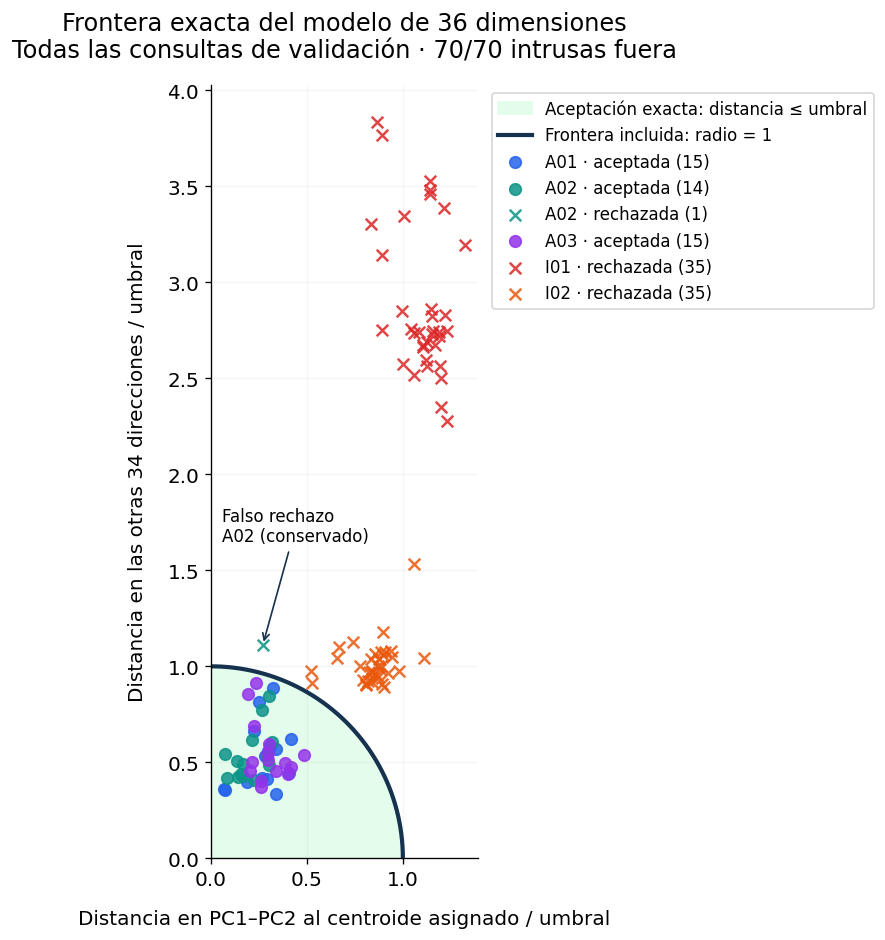

Distancia al origen en este gráfico = distancia completa / umbral.
Intrusas aceptadas: 0/70. Autorizadas aceptadas: 44/45.
El falso rechazo también se muestra. No se seleccionaron muestras para mejorar la figura.


In [9]:
# Descomposición exacta de la distancia al centroide elegido en 36D.
centro_asignado = distancias.argmin(axis=1)
delta = Z - centros[centro_asignado]
delta_plano = delta @ pca.components_[:2].T
d_plano = np.linalg.norm(delta_plano, axis=1)
d_restante = np.sqrt(np.maximum(dmin**2 - d_plano**2, 0.0))
x = d_plano / tau
y = d_restante / tau

fig, ax = plt.subplots(figsize=(11, 8))
angulo = np.linspace(0, np.pi/2, 250)
ax.fill(np.r_[0, np.cos(angulo), 0], np.r_[0, np.sin(angulo), 0],
        color="#DCFCE7", alpha=0.8, label="Aceptación exacta: distancia ≤ umbral")
ax.plot(np.cos(angulo), np.sin(angulo), color="#16324F", lw=2.5,
        label="Frontera incluida: radio = 1")
clases_exactas = ["A01", "A02", "A03", "I01", "I02"]
for clase in clases_exactas:
    for ok, marcador in [(True, "o"), (False, "x")]:
        m = val & (identidad == clase) & (aceptada == ok)
        if m.any():
            estado = "aceptada" if ok else "rechazada"
            ax.scatter(x[m], y[m], color=colores[clase], marker=marcador,
                       s=48, alpha=0.85, label=f"{clase} · {estado} ({m.sum()})")
falso_rechazo = val & (grupo_real == "autorizado") & (~aceptada)
i = np.flatnonzero(falso_rechazo)[0]
ax.annotate("Falso rechazo\nA02 (conservado)", (x[i], y[i]),
            xytext=(0.06, 1.65), fontsize=10,
            arrowprops={"arrowstyle":"->", "color":"#16324F"})
ax.set_aspect("equal", adjustable="box")
ax.set_xlim(left=0); ax.set_ylim(bottom=0)
ax.set_xlabel("Distancia en PC1–PC2 al centroide asignado / umbral", labelpad=12)
ax.set_ylabel("Distancia en las otras 34 direcciones / umbral", labelpad=12)
ax.set_title("Frontera exacta del modelo de 36 dimensiones\n"
             "Todas las consultas de validación · 70/70 intrusas fuera", pad=16)
ax.legend(loc="upper left", bbox_to_anchor=(1.02,1), fontsize=10)
ax.grid(alpha=0.12)
fig.tight_layout(); plt.show()
print("Distancia al origen en este gráfico = distancia completa / umbral.")
print("Intrusas aceptadas: 0/70. Autorizadas aceptadas: 44/45.")
print("El falso rechazo también se muestra. No se seleccionaron muestras para mejorar la figura.")


## Un círculo en PCA es una proyección, no la regla completa

La región real de aceptación es la unión de tres esferas de radio $\tau$ **en 36 dimensiones**. Al proyectarlas sobre PC1–PC2 con PCA sin blanqueo, sus proyecciones son discos de ese radio. Por eso podemos dibujar círculos, siempre con la misma escala en ambos ejes.

La proyección conserva solo parte de la distancia:

$$d_{36}^2=d_{PC1-PC2}^2+d_{restante}^2.$$

**Estar fuera de los tres círculos implica rechazo. Estar dentro de alguno no garantiza aceptación.** Una muestra puede parecer cercana en el dibujo y estar lejos en las otras 34 direcciones. Los círculos también pueden solaparse sin que eso implique confusión en el espacio completo.

Izquierda: color indica identidad real; círculo pequeño = aceptada; cruz = rechazada. Los círculos grandes discontinuos muestran el radio proyectado y las X negras los centroides. Derecha: usamos la distancia completa dividida por el umbral, para mostrar la regla exacta. A la izquierda de la línea 1 se acepta; a la derecha se rechaza; exactamente en 1 se acepta. La altura de los puntos dentro de cada fila solo separa visualmente las muestras.


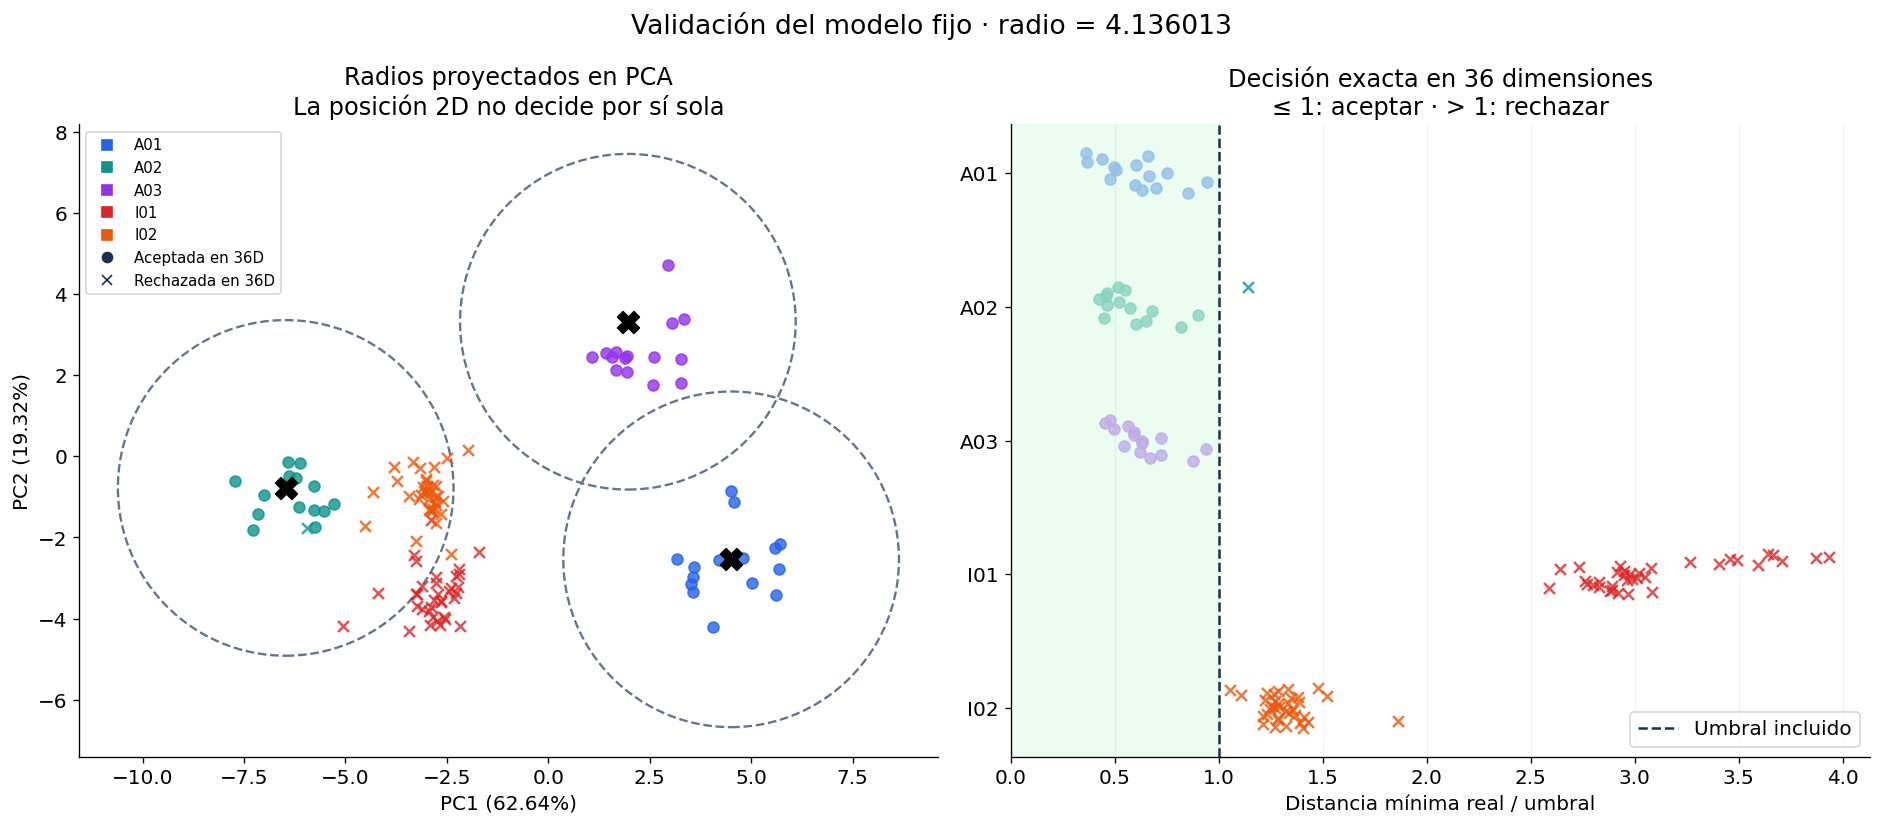

In [10]:
fig, (ax, radial) = plt.subplots(1, 2, figsize=(16, 7))
for centro in C:
    ax.add_patch(Circle(centro[:2], tau, fill=False, color="#64748B",
                        linestyle="--", linewidth=1.4))
ax.scatter(C[:, 0], C[:, 1], c="black", marker="X", s=170, zorder=5)
clases = ["A01", "A02", "A03", "I01", "I02"]
for i, clase in enumerate(clases):
    m = val & (identidad == clase)
    for ok, marcador in [(True, "o"), (False, "x")]:
        sub = m & (aceptada == ok)
        ax.scatter(P[sub, 0], P[sub, 1], c=colores[clase], marker=marcador,
                   s=43, alpha=0.8)
        valores = dmin[sub] / tau
        radial.scatter(valores, i + np.linspace(-0.15, 0.15, len(valores)),
                       c=colores[clase], marker=marcador, s=43, alpha=0.8)
ax.set_aspect("equal", adjustable="datalim")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.2%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.2%})")
ax.set_title("Radios proyectados en PCA\nLa posición 2D no decide por sí sola")
leyenda = [Line2D([], [], color=colores[c], marker="s", linestyle="", label=c) for c in clases]
leyenda += [Line2D([], [], color="#16324F", marker="o", linestyle="", label="Aceptada en 36D"),
            Line2D([], [], color="#16324F", marker="x", linestyle="", label="Rechazada en 36D")]
ax.legend(handles=leyenda, loc="upper left", fontsize=9)
radial.axvspan(0, 1, color="#DCFCE7", alpha=0.6)
radial.axvline(1, color="#16324F", linestyle="--", label="Umbral incluido")
radial.set_yticks(range(5), clases)
radial.invert_yaxis()
radial.set_xlim(left=0)
radial.set_xlabel("Distancia mínima real / umbral")
radial.set_title("Decisión exacta en 36 dimensiones\n≤ 1: aceptar · > 1: rechazar")
radial.grid(axis="x", alpha=0.15)
radial.legend(loc="lower right")
fig.suptitle(f"Validación del modelo fijo · radio = {tau:.6f}", fontsize=16)
plt.tight_layout(); plt.show()


## Vista PCA en tres dimensiones: una perspectiva más completa

Ahora añadimos **PC3**, que recoge aproximadamente 11,75 % adicional. Entre PC1, PC2 y PC3 se conserva **93,71 % de la varianza** de entrenamiento. Los dos paneles muestran los mismos puntos desde ángulos distintos; no son dos ajustes diferentes.

Las superficies transparentes son esferas de radio igual al umbral, centradas en los centroides proyectados. Se representan con la misma escala geométrica en los tres ejes. **Círculos pequeños = aceptadas; cruces = rechazadas según las 36 dimensiones.** Los colores indican identidad real: rojo y naranja corresponden a intrusas.

En esta validación se rechazaron realmente las **70 intrusas**. Sin embargo, **23 de ellas aparecen dentro de alguna esfera en tres dimensiones**. La proyección todavía omite 33 direcciones y puede reducir bastante una distancia concreta. Conservar el 93,71 % de la varianza global no significa conservar el 93,71 % de todas las distancias ni del reconocimiento.

Por eso, una cruz dentro de una esfera dibujada **no es una intrusa aceptada**: es una muestra rechazada cuya proyección parece cercana. No cambiamos el radio para ocultarlo. El gráfico de distancia completa del apartado anterior muestra la decisión exacta.


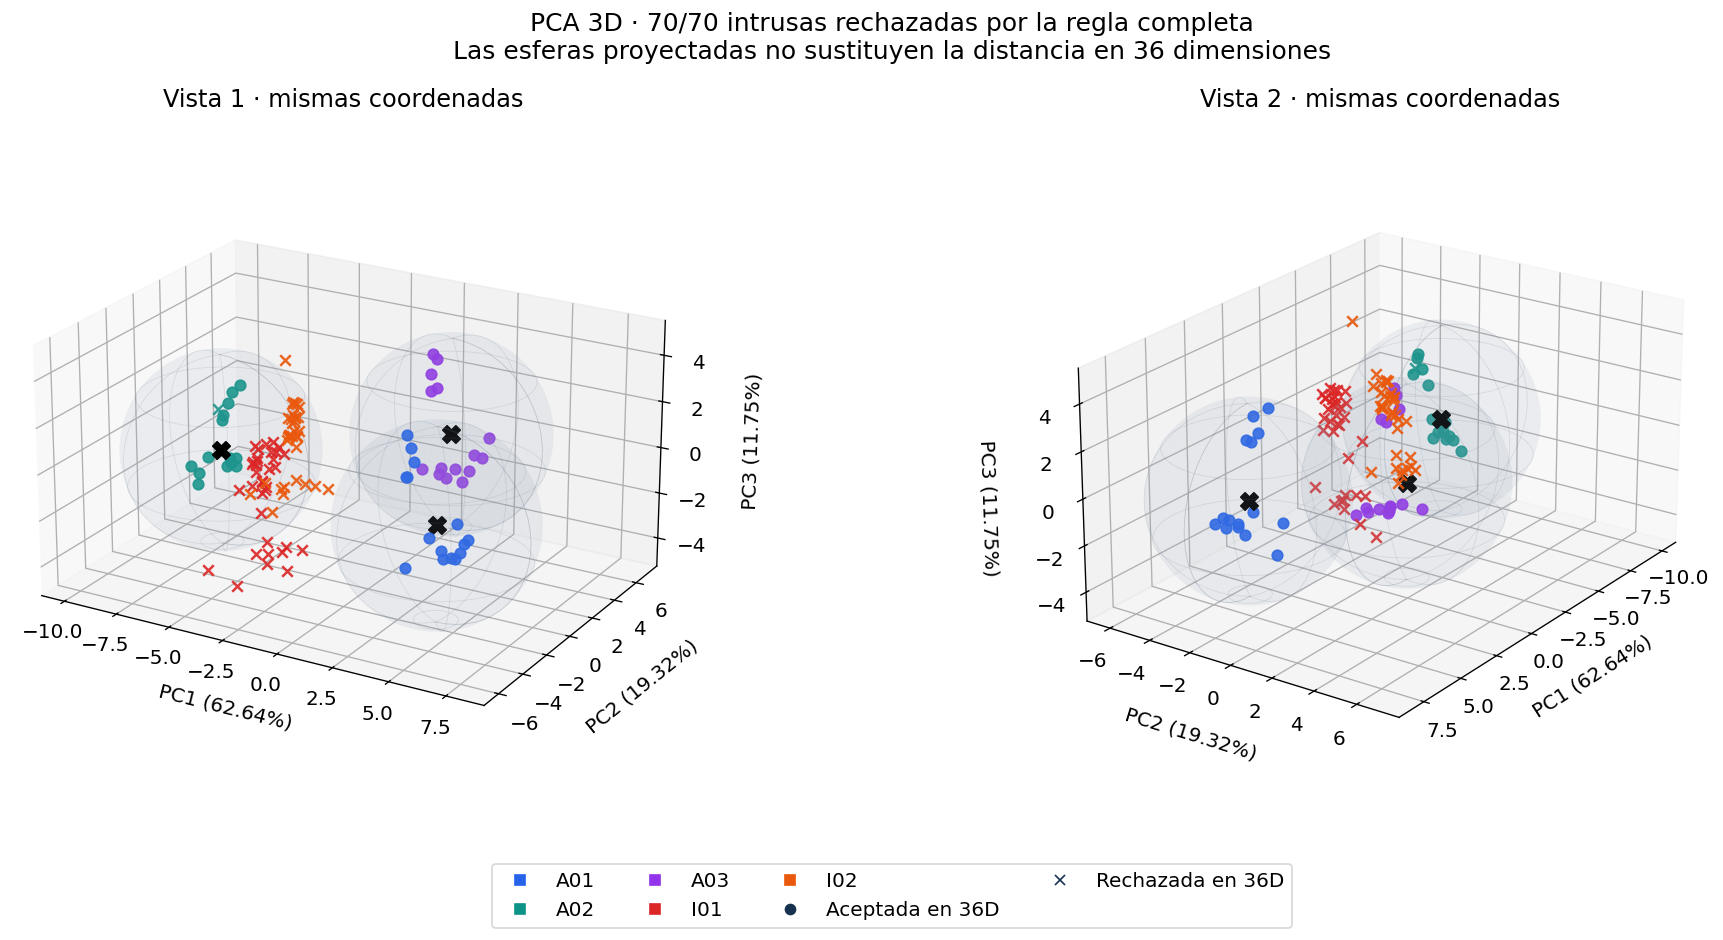

Varianza acumulada PC1–PC3: 93.71%
Intrusas aceptadas en 36 dimensiones: 0/70
Intrusas rechazadas que parecen dentro de una esfera 3D: 23


In [11]:
# Mismo PCA y mismo modelo: añadimos PC3, sin volver a entrenar K-means.
fig = plt.figure(figsize=(17, 8))
u = np.linspace(0, 2*np.pi, 48)
v = np.linspace(0, np.pi, 30)
sx = tau * np.outer(np.cos(u), np.sin(v))
sy = tau * np.outer(np.sin(u), np.sin(v))
sz = tau * np.outer(np.ones_like(u), np.cos(v))
lim_min = np.minimum(P[val, :3].min(axis=0), C[:, :3].min(axis=0)-tau)-0.5
lim_max = np.maximum(P[val, :3].max(axis=0), C[:, :3].max(axis=0)+tau)+0.5
for panel, azimut in enumerate([-60, 35], start=1):
    ax = fig.add_subplot(1, 2, panel, projection="3d")
    for centro in C:
        ax.plot_surface(sx+centro[0], sy+centro[1], sz+centro[2],
                        color="#94A3B8", alpha=0.065, linewidth=0, shade=False)
        ax.plot_wireframe(sx+centro[0], sy+centro[1], sz+centro[2],
                          rstride=10, cstride=9, color="#64748B", alpha=0.16, linewidth=0.5)
    ax.scatter(C[:,0], C[:,1], C[:,2], c="black", marker="X", s=110, depthshade=False)
    for clase in clases:
        for ok, marcador in [(True,"o"), (False,"x")]:
            m = val & (identidad == clase) & (aceptada == ok)
            ax.scatter(P[m,0], P[m,1], P[m,2], c=colores[clase], marker=marcador,
                       s=40, alpha=0.9, depthshade=False)
    ax.set(xlim=(lim_min[0],lim_max[0]), ylim=(lim_min[1],lim_max[1]),
           zlim=(lim_min[2],lim_max[2]))
    ax.set_box_aspect(lim_max-lim_min)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.2%})", labelpad=10)
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.2%})", labelpad=10)
    ax.set_zlabel(f"PC3 ({pca.explained_variance_ratio_[2]:.2%})", labelpad=10)
    ax.view_init(elev=22, azim=azimut)
    ax.set_title(f"Vista {panel} · mismas coordenadas", pad=18)
fig.legend(handles=leyenda, loc="lower center", ncol=4, bbox_to_anchor=(0.5,0.015))
fig.suptitle("PCA 3D · 70/70 intrusas rechazadas por la regla completa\n"
             "Las esferas proyectadas no sustituyen la distancia en 36 dimensiones", fontsize=15)
fig.subplots_adjust(left=0.01,right=0.96,bottom=0.16,top=0.85,wspace=0.15)
plt.show()
d3 = np.linalg.norm(P[:,None,:3]-C[None,:,:3], axis=2).min(axis=1)
intrusas = val & (grupo_real == "intruso")
print(f"Varianza acumulada PC1–PC3: {pca.explained_variance_ratio_[:3].sum():.2%}")
print(f"Intrusas aceptadas en 36 dimensiones: {int((intrusas & aceptada).sum())}/{int(intrusas.sum())}")
print("Intrusas rechazadas que parecen dentro de una esfera 3D:",
      int((intrusas & (~aceptada) & (d3 <= tau)).sum()))


## Curva usada para interpretar la calibración

La siguiente celda reproduce los candidatos y tasas **a modo explicativo sobre la validación ya utilizada**. Marca el umbral guardado y no lo reemplaza ni lo escribe en el modelo. En esa validación se aceptaron 44/45 autorizadas y se rechazaron 70/70 intrusas: FAR = 0 % y FRR ≈ 2,22 %. Estos son resultados de calibración, no una nueva evaluación independiente.

En un caso futuro exactamente en el límite, la regla del proyecto acepta. Si se quisiera una política de frontera diferente habría que definirla, evaluarla y documentarla; no cambiarla silenciosamente según cada muestra.


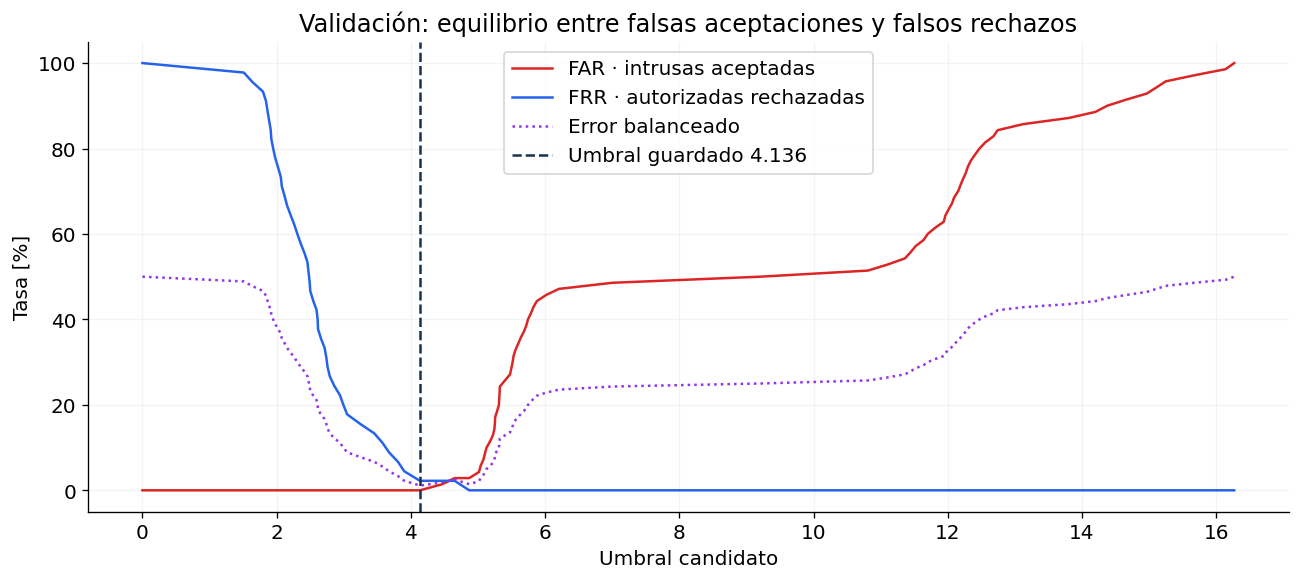

Identidad | consultas | aceptadas | rechazadas
A01       |        15 |        15 |          0
A02       |        15 |        14 |          1
A03       |        15 |        15 |          0
I01       |        35 |         0 |         35
I02       |        35 |         0 |         35
Rechazadas realmente, aunque están dentro de algún círculo PCA: 41


In [12]:
dv = dmin[val]
autorizada_real = grupo_real[val] == "autorizado"
valores = np.unique(dv)
candidatos = np.r_[0, (valores[:-1] + valores[1:])/2, valores[-1]]
far = np.array([(dv[~autorizada_real] <= t).mean() for t in candidatos])
frr = np.array([(dv[autorizada_real] > t).mean() for t in candidatos])
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(candidatos, 100*far, label="FAR · intrusas aceptadas", color="#DC2626")
ax.plot(candidatos, 100*frr, label="FRR · autorizadas rechazadas", color="#2563EB")
ax.plot(candidatos, 50*(far+frr), label="Error balanceado", color="#9333EA", linestyle=":")
ax.axvline(tau, color="#16324F", linestyle="--", label=f"Umbral guardado {tau:.3f}")
ax.set(xlabel="Umbral candidato", ylabel="Tasa [%]",
       title="Validación: equilibrio entre falsas aceptaciones y falsos rechazos")
ax.legend(); ax.grid(alpha=0.15); plt.tight_layout(); plt.show()
print("Identidad | consultas | aceptadas | rechazadas")
for clase in clases:
    m = val & (identidad == clase)
    print(f"{clase:9} | {m.sum():9} | {aceptada[m].sum():9} | {(~aceptada[m]).sum():10}")
# Cuántas muestras parecen dentro de un círculo pero la regla completa rechaza.
d2 = np.linalg.norm(P[:, None, :2] - C[None, :, :2], axis=2).min(axis=1)
print("Rechazadas realmente, aunque están dentro de algún círculo PCA:",
      int((val & (~aceptada) & (d2 <= tau)).sum()))


## Procedencia

Datos y parámetros tomados de la guía didáctica entregada el 24/10/2026, basada en el modelo combinado `20261023T222326_850333Z` y el repositorio en commit `eb97d38ab95d1f3a776734b2b2fa36ed54df37b9`. No se consultaron imágenes de prueba final ni se recalibró el reconocedor. La diferencia entre punto en el plano y distancia completa explica por qué este dibujo no debe utilizarse como sustituto del clasificador.

Fuente del procedimiento: [guía del modelo combinado](https://github.com/peterortiz03/Trabajo-Final-IA1/blob/eb97d38ab95d1f3a776734b2b2fa36ed54df37b9/documentos/guias/modelo_combinado_anguli_v1.md).
